# Assignment 4 — Distributed Stream Processing. Done by Ayazhan Sailauova BDA-2402

In [1]:
import sys, json, time, platform, queue, threading, importlib.util
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from common import *          

DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 160)

print("Python :", platform.python_version())
print("pandas :", pd.__version__)
print("Individual variant / STUDENT_SEED:", STUDENT_SEED)

Python : 3.11.9
pandas : 2.3.3
Individual variant / STUDENT_SEED: 240791


## Part A. Streaming Architecture

In [2]:
initial  = [dict(e) for e in INITIAL_EVENTS]
extended = generate_extended_stream()            

save_events_csv(initial,  DATA_DIR / "events_initial.csv")
save_events_csv(extended, DATA_DIR / "events_extended.csv")

df_init = pd.DataFrame(initial)
df_ext  = pd.DataFrame(extended)

max_seen, out_of_order = "", []
for e in extended:
    if e["timestamp"] < max_seen:
        out_of_order.append(e["event_id"])
    max_seen = max(max_seen, e["timestamp"])

print(f"supplied events : {len(initial)}")
print(f"extended stream : {len(extended)} events, {extended[0]['timestamp']} .. {max(e['timestamp'] for e in extended)}")
print(f"out-of-order    : {out_of_order}")
print("job_type mix    :", dict(Counter(e['job_type'] for e in extended)))
df_ext.head(15)

supplied events : 10
extended stream : 108 events, 14:00:01 .. 14:01:59
out-of-order    : ['E045']
job_type mix    : {'ml': 31, 'image': 37, 'text': 19, 'simulation': 21}


,event_id,timestamp,research_group,job_type,duration_sec,status,cpu_pct,arrival_seq
0,E001,14:00:01,G01,ml,42,completed,61,1
1,E002,14:00:02,G02,image,75,completed,74,2
2,E003,14:00:03,G01,text,18,completed,38,3
3,E004,14:00:04,G03,simulation,95,failed,92,4
4,E005,14:00:05,G02,ml,51,completed,68,5
5,E006,14:00:06,G01,image,88,completed,81,6
6,E007,14:00:07,G03,ml,64,failed,89,7
7,E008,14:00:08,G02,text,22,completed,44,8
8,E009,14:00:09,G01,simulation,120,completed,94,9
9,E010,14:00:10,G03,image,70,completed,78,10


## Part B — Producer / consumer

In [3]:
def producer(events, q, delay=0.0):
    for ev in events:
        q.put(json.dumps(ev))         
        time.sleep(delay)
    q.put(None)                     

def consumer(q, valid, invalid):
    while (msg := q.get()) is not None:
        ev = json.loads(msg)      
        ok, errors = validate_event(ev)
        if ok:
            valid.append(ev)
        else:
            invalid.append({"event": ev, "errors": errors})

bad_events = [  
    {"event_id": "E998", "timestamp": "14:00:11", "research_group": "G02", "job_type": "quantum",
     "duration_sec": 30, "status": "completed", "cpu_pct": 50},
    {"event_id": "E999", "timestamp": "14:00:12", "research_group": "G01", "job_type": "ml",
     "duration_sec": -4, "status": "done"},
]

q = queue.Queue()
valid_events, invalid_events = [], []
t_cons = threading.Thread(target=consumer, args=(q, valid_events, invalid_events))
t_prod = threading.Thread(target=producer, args=(initial + bad_events, q, 0.05))
t_cons.start(); t_prod.start(); t_prod.join(); t_cons.join()

print(f"received {len(valid_events) + len(invalid_events)} messages -> "
      f"{len(valid_events)} valid, {len(invalid_events)} rejected")
for bad in invalid_events:
    print("  REJECTED", bad["event"]["event_id"], "->", bad["errors"])

received 12 messages -> 10 valid, 2 rejected
  REJECTED E998 -> ["job_type must be one of ('simulation', 'ml', 'image', 'text')"]
  REJECTED E999 -> ["missing fields: ['cpu_pct']"]


In [4]:
status_counts = Counter(e["status"] for e in valid_events)

job = defaultdict(lambda: {"completed": 0, "failed": 0, "durations": []})
grp = defaultdict(list)
for e in valid_events:
    job[e["job_type"]][e["status"]] += 1
    job[e["job_type"]]["durations"].append(e["duration_sec"])
    grp[e["research_group"]].append(e["cpu_pct"])

print(f"Completed jobs: {status_counts['completed']}   Failed jobs: {status_counts['failed']}\n")

partB_job = pd.DataFrame([
    {"Job type": t,
     "Completed": job[t]["completed"],
     "Failed": job[t]["failed"],
     "Average duration (s)": round(sum(job[t]["durations"]) / len(job[t]["durations"]), 2)}
    for t in ["ml", "image", "text", "simulation"]])

partB_cpu = pd.DataFrame([
    {"Research group": g, "Events": len(v), "Average CPU %": round(sum(v) / len(v), 2)}
    for g, v in sorted(grp.items())])

display(partB_job)
display(partB_cpu)
partB_job.to_csv(RESULTS_DIR / "partB_job_type.csv", index=False)
partB_cpu.to_csv(RESULTS_DIR / "partB_cpu_by_group.csv", index=False)

Completed jobs: 8   Failed jobs: 2



,Job type,Completed,Failed,Average duration (s)
0,ml,2,1,52.33
1,image,3,0,77.67
2,text,2,0,20.00
3,simulation,1,1,107.50


,Research group,Events,Average CPU %
0,G01,4,68.50
1,G02,3,62.00
2,G03,3,86.33


pandas cross-check passed


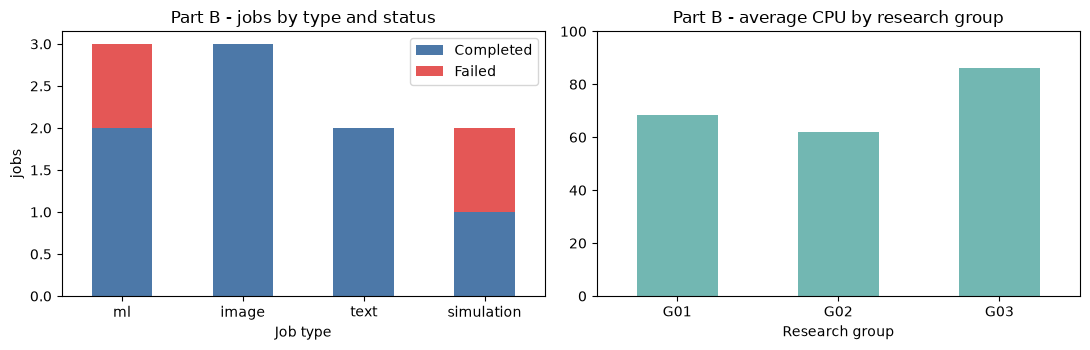

In [5]:
chk = df_init.groupby("job_type").agg(completed=("status", lambda s: (s == "completed").sum()),
                                      failed=("status", lambda s: (s == "failed").sum()),
                                      avg_duration=("duration_sec", "mean")).round(2)
chk_cpu = df_init.groupby("research_group")["cpu_pct"].mean().round(2)
for _, r in partB_job.iterrows():
    assert chk.loc[r["Job type"], "completed"] == r["Completed"]
    assert chk.loc[r["Job type"], "failed"] == r["Failed"]
    assert abs(chk.loc[r["Job type"], "avg_duration"] - r["Average duration (s)"]) < 1e-9
for _, r in partB_cpu.iterrows():
    assert abs(chk_cpu[r["Research group"]] - r["Average CPU %"]) < 1e-9
print("pandas cross-check passed")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
partB_job.set_index("Job type")[["Completed", "Failed"]].plot.bar(stacked=True, ax=ax[0], rot=0,
                                                                  color=["#4C78A8", "#E45756"])
ax[0].set_title("Part B - jobs by type and status"); ax[0].set_ylabel("jobs")
partB_cpu.set_index("Research group")["Average CPU %"].plot.bar(ax=ax[1], rot=0, color="#72B7B2")
ax[1].set_title("Part B - average CPU by research group"); ax[1].set_ylim(0, 100)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "partB_charts.png", dpi=150); plt.show()

In [6]:
ext_job = df_ext.groupby("job_type").agg(Completed=("status", lambda s: (s == "completed").sum()),
                                         Failed=("status", lambda s: (s == "failed").sum()),
                                         Avg_duration=("duration_sec", "mean")).round(2)
ext_cpu = df_ext.groupby("research_group")["cpu_pct"].agg(["count", "mean"]).round(2)
display(ext_job.loc[["ml", "image", "text", "simulation"]]); display(ext_cpu)

,Completed,Failed,Avg_duration
job_type,,,
ml,26,5,53.19
image,31,6,74.51
text,18,1,20.21
simulation,15,6,105.05


,count,mean
research_group,,
G01,39,70.67
G02,32,73.28
G03,37,70.16


## Part C — Windowed Stream Processing

In [7]:
def hms_to_sec(hms):
    h, m, s = map(int, hms.split(":"))
    return h * 3600 + m * 60 + s

def sec_to_hms(x):
    return f"{x // 3600:02d}:{x // 60 % 60:02d}:{x % 60:02d}"

class TumblingWindowProcessor:
    def __init__(self, size_sec=5, allowed_lateness_sec=5):
        self.size, self.lateness = size_sec, allowed_lateness_sec
        self.open = {}                 # window_start -> accumulator
        self.max_event_time = None
        self.emitted, self.late_dropped = [], []

    def process(self, ev):
        t = hms_to_sec(ev["timestamp"])
        self.max_event_time = t if self.max_event_time is None else max(self.max_event_time, t)
        watermark = self.max_event_time - self.lateness
        start = t - t % self.size
        if start + self.size <= watermark:        
            self.late_dropped.append(ev["event_id"])
            return
        acc = self.open.setdefault(start, {"ids": [], "failed": 0, "cpu_sum": 0})
        acc["ids"].append(ev["event_id"])
        acc["failed"] += ev["status"] == "failed"
        acc["cpu_sum"] += ev["cpu_pct"]
        for s in sorted(k for k in self.open if k + self.size <= watermark):
            self._emit(s, closed_by=ev["event_id"])

    def _emit(self, s, closed_by):
        acc = self.open.pop(s)
        n = len(acc["ids"])
        self.emitted.append({
            "Window": f"{sec_to_hms(s)}–{sec_to_hms(s + self.size)}",
            "Events": ", ".join(acc["ids"]),
            "Count": n,
            "Failed": acc["failed"],
            "Failure rate %": round(100 * acc["failed"] / n, 2),
            "Average CPU": round(acc["cpu_sum"] / n, 2),
            "Emitted after": closed_by,
        })

    def flush(self):                               
        for s in sorted(self.open):
            self._emit(s, closed_by="end-of-stream")
        return pd.DataFrame(self.emitted)

p10 = TumblingWindowProcessor()
for ev in initial:
    p10.process(ev)
partC_10 = p10.flush()
print("Windows using ONLY the 10 supplied events (last window is incomplete):")
display(partC_10)

Windows using ONLY the 10 supplied events (last window is incomplete):


,Window,Events,Count,Failed,Failure rate %,Average CPU,Emitted after
0,14:00:00–14:00:05,"E001, E002, E003, E004",4,1,25.0,66.25,E010
1,14:00:05–14:00:10,"E005, E006, E007, E008, E009",5,1,20.0,75.20,end-of-stream
2,14:00:10–14:00:15,E010,1,0,0.0,78.00,end-of-stream


In [8]:
pC = TumblingWindowProcessor()
for ev in extended:                
    pC.process(ev)
partC = pC.flush().sort_values("Window").reset_index(drop=True)
print(f"{len(extended)} events -> {len(partC)} windows, late events dropped: {pC.late_dropped}")
print("\nRequired report table (first three windows):")
display(partC.head(3)[["Window", "Events", "Count", "Failure rate %", "Average CPU"]])
partC.to_csv(RESULTS_DIR / "partC_windows_extended.csv", index=False)
partC_10.to_csv(RESULTS_DIR / "partC_windows_10_events.csv", index=False)
partC

108 events -> 24 windows, late events dropped: []

Required report table (first three windows):


,Window,Events,Count,Failure rate %,Average CPU
0,14:00:00–14:00:05,"E001, E002, E003, E004",4,25.0,66.25
1,14:00:05–14:00:10,"E005, E006, E007, E008, E009",5,20.0,75.20
2,14:00:10–14:00:15,"E010, E011",2,0.0,74.50


,Window,Events,Count,Failed,Failure rate %,Average CPU,Emitted after
0,14:00:00–14:00:05,"E001, E002, E003, E004",4,1,25.00,66.25,E010
1,14:00:05–14:00:10,"E005, E006, E007, E008, E009",5,1,20.00,75.20,E012
2,14:00:10–14:00:15,"E010, E011",2,0,0.00,74.50,E016
3,14:00:15–14:00:20,"E012, E013, E014, E015",4,1,25.00,70.50,E023
4,14:00:20–14:00:25,"E016, E017, E018, E019, E020, E021, E022",7,0,0.00,74.71,E025
5,14:00:25–14:00:30,"E023, E024",2,2,100.00,73.00,E030
6,14:00:30–14:00:35,"E025, E026, E027, E028, E029",5,1,20.00,79.00,E033
7,14:00:35–14:00:40,"E030, E031, E032",3,1,33.33,95.33,E040
8,14:00:40–14:00:45,"E033, E034, E035, E036, E037, E038, E039",7,0,0.00,62.57,E048
9,14:00:45–14:00:50,"E040, E041, E042, E043, E044, E045, E046, E047",8,2,25.00,70.12,E054


streaming result == batch result for all 24 windows


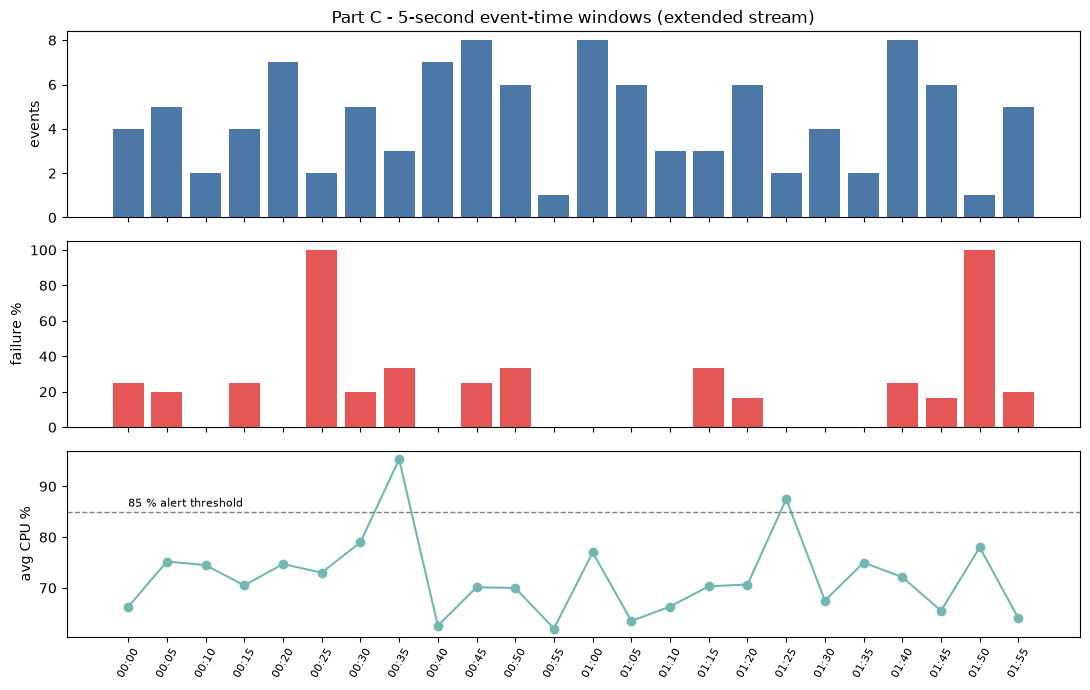

Monitoring alerts (failure rate >= 50 % or avg CPU >= 85 %):


,Window,Count,Failure rate %,Average CPU
5,14:00:25–14:00:30,2,100.00,73.00
7,14:00:35–14:00:40,3,33.33,95.33
17,14:01:25–14:01:30,2,0.00,87.50
22,14:01:50–14:01:55,1,100.00,78.00


In [9]:
df_ext["ws"] = df_ext["timestamp"].map(hms_to_sec) // 5 * 5
batch = df_ext.groupby("ws").agg(Count=("event_id", "size"),
                                 fr=("status", lambda s: round(100 * (s == "failed").mean(), 2)),
                                 cpu=("cpu_pct", lambda s: round(s.mean(), 2))).reset_index()
assert list(batch["Count"]) == list(partC["Count"])
assert list(batch["fr"]) == list(partC["Failure rate %"])
assert list(batch["cpu"]) == list(partC["Average CPU"])
print("streaming result == batch result for all", len(batch), "windows")

fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
x = partC["Window"].str[3:8]
ax[0].bar(x, partC["Count"], color="#4C78A8"); ax[0].set_ylabel("events")
ax[1].bar(x, partC["Failure rate %"], color="#E45756"); ax[1].set_ylabel("failure %")
ax[2].plot(x, partC["Average CPU"], marker="o", color="#72B7B2"); ax[2].set_ylabel("avg CPU %")
ax[2].axhline(85, ls="--", c="grey", lw=1); ax[2].text(0, 86, "85 % alert threshold", fontsize=8)
ax[0].set_title("Part C - 5-second event-time windows (extended stream)")
plt.xticks(rotation=60, fontsize=8); plt.tight_layout()
plt.savefig(RESULTS_DIR / "partC_windows.png", dpi=150); plt.show()

alerts = partC[(partC["Failure rate %"] >= 50) | (partC["Average CPU"] >= 85)]
print("Monitoring alerts (failure rate >= 50 % or avg CPU >= 85 %):")
display(alerts[["Window", "Count", "Failure rate %", "Average CPU"]])

## Part D — Spark Structured Streaming

In [10]:
df_ext["window_start"] = df_ext["ws"].map(sec_to_hms)
df_ext["window_end"] = (df_ext["ws"] + 5).map(sec_to_hms)
expected_D = (df_ext.groupby(["window_start", "window_end", "job_type"])
              .agg(count=("event_id", "size"), avg_duration=("duration_sec", "mean"))
              .round(2).reset_index())
expected_D.to_csv(RESULTS_DIR / "partD_expected_pandas.csv", index=False)
print(len(expected_D), "expected (window, job_type) rows; first 10:")
expected_D.head(10)

65 expected (window, job_type) rows; first 10:


,window_start,window_end,job_type,count,avg_duration
0,14:00:00,14:00:05,image,1,75.0
1,14:00:00,14:00:05,ml,1,42.0
2,14:00:00,14:00:05,simulation,1,95.0
3,14:00:00,14:00:05,text,1,18.0
4,14:00:05,14:00:10,image,1,88.0
5,14:00:05,14:00:10,ml,2,57.5
6,14:00:05,14:00:10,simulation,1,120.0
7,14:00:05,14:00:10,text,1,22.0
8,14:00:10,14:00:15,image,2,68.5
9,14:00:15,14:00:20,image,2,85.5


In [11]:
import os, sys, glob, subprocess

jdk17 = sorted(glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*"))
print("JDK 17 folders found:", jdk17)
assert jdk17, "Java 17 not found"

os.environ["JAVA_HOME"] = jdk17[-1]
os.environ["PATH"] = os.path.join(jdk17[-1], "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("Using JAVA_HOME =", os.environ["JAVA_HOME"])
print(subprocess.run([os.path.join(jdk17[-1], "bin", "java.exe"), "-version"],
                     capture_output=True, text=True).stderr)

JDK 17 folders found: ['C:\\Program Files\\Eclipse Adoptium\\jdk-17.0.20.101-hotspot']
Using JAVA_HOME = C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [12]:
import os, sys, glob, subprocess

jdk17 = sorted(glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*"))
print("JDK 17 folders found:", jdk17)
assert jdk17, "Java 17 not found - install Temurin 17 (.msi) from adoptium.net first"

os.environ["JAVA_HOME"] = jdk17[-1]
os.environ["PATH"] = os.path.join(jdk17[-1], "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("JAVA_HOME =", os.environ["JAVA_HOME"])
print(subprocess.run([os.path.join(jdk17[-1], "bin", "java.exe"), "-version"],
                     capture_output=True, text=True).stderr)

JDK 17 folders found: ['C:\\Program Files\\Eclipse Adoptium\\jdk-17.0.20.101-hotspot']
JAVA_HOME = C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [13]:
import os, sys, glob, subprocess

search = [r"C:\Program Files\Eclipse Adoptium\*",
          r"C:\Program Files\Java\*",
          r"C:\Program Files\Microsoft\jdk*",
          r"C:\Program Files\Zulu\*",
          os.path.expandvars(r"%LOCALAPPDATA%\Programs\Eclipse Adoptium\*")]
all_jdks = [p for pat in search for p in glob.glob(pat)]
print("All Java folders found:")
for p in all_jdks:
    print("  ", p)

jdk17 = sorted(p for p in all_jdks if "17" in os.path.basename(p))
assert jdk17, "No Java 17 folder found - send me the list above"

os.environ["JAVA_HOME"] = jdk17[-1]
os.environ["PATH"] = os.path.join(jdk17[-1], "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("\nUsing JAVA_HOME =", os.environ["JAVA_HOME"])
print(subprocess.run([os.path.join(jdk17[-1], "bin", "java.exe"), "-version"],
                     capture_output=True, text=True).stderr)

All Java folders found:
   C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
   C:\Program Files\Eclipse Adoptium\jdk-25.0.5.8-hotspot

Using JAVA_HOME = C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment Temurin-17.0.20.1+1 (build 17.0.20.1+1)
OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)



In [14]:
import os, sys, glob, subprocess

# Java 17
jdk17 = sorted(glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*"))
assert jdk17, "Java 17 not found"
os.environ["JAVA_HOME"] = jdk17[-1]

# Hadoop helper files for Windows
os.environ["HADOOP_HOME"] = r"C:\hadoop"
assert os.path.exists(r"C:\hadoop\bin\winutils.exe"), "winutils.exe missing in C:\\hadoop\\bin"
assert os.path.exists(r"C:\hadoop\bin\hadoop.dll"), "hadoop.dll missing in C:\\hadoop\\bin"

os.environ["PATH"] = (os.path.join(jdk17[-1], "bin") + os.pathsep +
                      r"C:\hadoop\bin" + os.pathsep + os.environ["PATH"])
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("JAVA_HOME   =", os.environ["JAVA_HOME"])
print("HADOOP_HOME =", os.environ["HADOOP_HOME"])
print(subprocess.run([r"C:\hadoop\bin\winutils.exe", "ls", "C:\\"],
                     capture_output=True, text=True).returncode == 0 and "winutils OK")

JAVA_HOME   = C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
HADOOP_HOME = C:\hadoop
winutils OK


In [16]:
import importlib.util
RUN_SPARK = importlib.util.find_spec("pyspark") is not None
print("pyspark installed:", RUN_SPARK)
if RUN_SPARK:
    import pyspark
    from pyspark.sql import SparkSession, functions as F
    from pyspark.sql.types import StructType, StructField, StringType, IntegerType
    from spark_streaming_job import prepare_stream_files

    print("Spark version:", pyspark.__version__)
    print("micro-batch files written:", prepare_stream_files(events_per_file=12))

    spark = (SparkSession.builder.appName("AITU-A4-PartD")
             .master("local[3]")
             .config("spark.sql.shuffle.partitions", "3")
             .config("spark.sql.session.timeZone", "UTC")
             .getOrCreate())
    spark.sparkContext.setLogLevel("WARN")

    schema = StructType([
        StructField("event_id", StringType()), StructField("timestamp", StringType()),
        StructField("research_group", StringType()), StructField("job_type", StringType()),
        StructField("duration_sec", IntegerType()), StructField("status", StringType()),
        StructField("cpu_pct", IntegerType()), StructField("arrival_seq", IntegerType())])

    stream_df = (spark.readStream
                 .option("header", True)
                 .option("maxFilesPerTrigger", 1)
                 .schema(schema)
                 .csv(str(DATA_DIR / "stream_input")))
    print("isStreaming:", stream_df.isStreaming)

pyspark installed: True
Spark version: 3.5.3
micro-batch files written: 9
isStreaming: True


In [17]:
if RUN_SPARK:
    events_sdf = (stream_df
        .withColumn("event_time", F.to_timestamp(
            F.concat_ws(" ", F.lit(EVENT_DATE), F.col("timestamp")), "yyyy-MM-dd HH:mm:ss"))
        .filter(F.col("event_time").isNotNull()
                & F.col("job_type").isin("simulation", "ml", "image", "text")
                & (F.col("duration_sec") > 0)))

    windowed = (events_sdf
        .withWatermark("event_time", "10 seconds")
        .groupBy(F.window("event_time", "5 seconds"), F.col("job_type"))
        .agg(F.count("*").alias("count"),
             F.round(F.avg("duration_sec"), 2).alias("avg_duration")))
    windowed.printSchema()

    import tempfile
    query = (windowed.writeStream
             .outputMode("complete")
             .format("memory")
             .queryName("job_type_windows")
             .option("checkpointLocation", tempfile.mkdtemp(prefix="a4_ckpt_"))
             .start())
    query.processAllAvailable()          
    print("micro-batches processed:", (query.lastProgress or {}).get("batchId", -1) + 1)

root
 |-- window: struct (nullable = false)
 |    |-- start: timestamp (nullable = true)
 |    |-- end: timestamp (nullable = true)
 |-- job_type: string (nullable = true)
 |-- count: long (nullable = false)
 |-- avg_duration: double (nullable = true)

micro-batches processed: 9


In [18]:
if RUN_SPARK:
    spark_D = spark.sql(r'''
        SELECT window,
               date_format(window.start, 'HH:mm:ss') AS window_start,
               date_format(window.end,   'HH:mm:ss') AS window_end,
               job_type, count, avg_duration
        FROM job_type_windows
        ORDER BY window.start, job_type''')
    spark_D.show(20, truncate=False)
    spark_pd = spark_D.drop("window").toPandas()
    spark_pd.to_csv(RESULTS_DIR / "partD_spark_output.csv", index=False)

    m = spark_pd.merge(expected_D, on=["window_start", "window_end", "job_type"],
                       suffixes=("_spark", "_pandas"), how="outer", indicator=True)
    same = (m["_merge"] == "both").all() and (m["count_spark"] == m["count_pandas"]).all() \
           and ((m["avg_duration_spark"] - m["avg_duration_pandas"]).abs() < 0.01).all()
    print("Spark output identical to pandas expectation:", same, f"({len(spark_pd)} rows)")
    print(query.lastProgress)
    query.stop()
    spark.stop()
else:
    print("pyspark is not installed in this kernel - install it (see README) and re-run Part D.")

+------------------------------------------+------------+----------+----------+-----+------------+
|window                                    |window_start|window_end|job_type  |count|avg_duration|
+------------------------------------------+------------+----------+----------+-----+------------+
|{2026-10-31 14:00:00, 2026-10-31 14:00:05}|14:00:00    |14:00:05  |image     |1    |75.0        |
|{2026-10-31 14:00:00, 2026-10-31 14:00:05}|14:00:00    |14:00:05  |ml        |1    |42.0        |
|{2026-10-31 14:00:00, 2026-10-31 14:00:05}|14:00:00    |14:00:05  |simulation|1    |95.0        |
|{2026-10-31 14:00:00, 2026-10-31 14:00:05}|14:00:00    |14:00:05  |text      |1    |18.0        |
|{2026-10-31 14:00:05, 2026-10-31 14:00:10}|14:00:05    |14:00:10  |image     |1    |88.0        |
|{2026-10-31 14:00:05, 2026-10-31 14:00:10}|14:00:05    |14:00:10  |ml        |2    |57.5        |
|{2026-10-31 14:00:05, 2026-10-31 14:00:10}|14:00:05    |14:00:10  |simulation|1    |120.0       |
|{2026-10-

## Part E — Throughput and latency

In [19]:
from load_test import run_inproc_level, run_inproc_capacity, bottleneck_label
import psutil
print("CPU cores:", psutil.cpu_count(logical=True), "| platform:", platform.platform())

rows = []
for rate, dur in [(10, 10), (100, 10), (500, 10), (2000, 5), (5000, 5)]:
    r = run_inproc_level(rate, duration_s=dur)
    r["bottleneck"] = bottleneck_label(r)
    rows.append(r)
    print(f"{rate:>5} ev/s done")
partE = pd.DataFrame(rows)
partE.to_csv(RESULTS_DIR / "partE_load_levels.csv", index=False)
partE[["input_rate", "sent", "processed", "observed_throughput", "avg_latency_ms",
       "p95_latency_ms", "cpu_pct", "bottleneck"]]

CPU cores: 12 | platform: Windows-10-10.0.19045-SP0
   10 ev/s done
  100 ev/s done
  500 ev/s done
 2000 ev/s done
 5000 ev/s done


,input_rate,sent,processed,observed_throughput,avg_latency_ms,p95_latency_ms,cpu_pct,bottleneck
0,10,100,100,10.1,0.488,0.639,1.6,none - limited by input rate; consumer mostly ...
1,100,1000,1000,100.1,0.349,0.506,2.2,none - limited by input rate; consumer mostly ...
2,500,5000,5000,500.1,0.302,0.479,2.5,none - limited by input rate; consumer mostly ...
3,2000,10000,10000,1999.8,0.380,0.597,4.4,none - limited by input rate; consumer mostly ...
4,5000,25000,25000,4998.1,0.378,0.602,9.4,none - limited by input rate; consumer mostly ...


,mode,batch_consumer,events,max_throughput,cpu_pct
0,inproc-capacity,False,200000,103265.6,97.6
1,inproc-capacity,True,200000,102823.2,97.6


batch-draining consumer: -0.4% maximum throughput
headroom at 500 ev/s: 207x


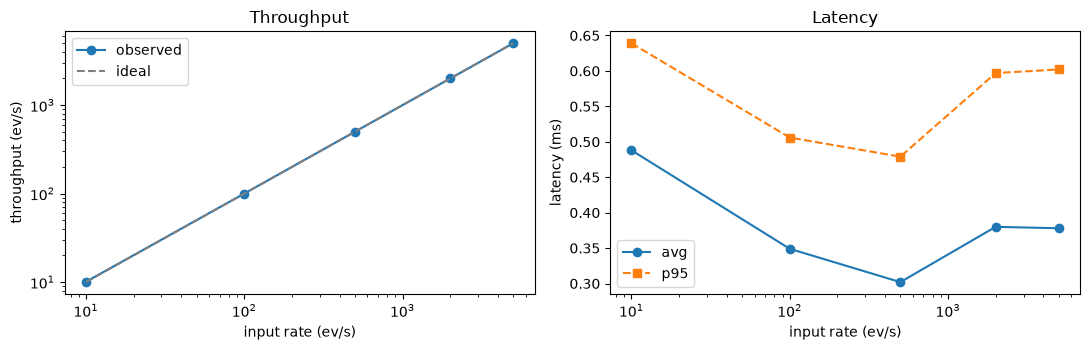

In [20]:
cap = pd.DataFrame([run_inproc_capacity(200_000, batch=False),
                    run_inproc_capacity(200_000, batch=True)])
cap.to_csv(RESULTS_DIR / "partE_capacity.csv", index=False)
gain = cap.loc[1, "max_throughput"] / cap.loc[0, "max_throughput"] - 1
display(cap)
print(f"batch-draining consumer: {gain:+.1%} maximum throughput")
print(f"headroom at 500 ev/s: {cap.loc[0, 'max_throughput'] / 500:.0f}x")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(partE["input_rate"], partE["observed_throughput"], "o-", label="observed")
ax[0].plot(partE["input_rate"], partE["input_rate"], "--", c="grey", label="ideal")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend()
ax[0].set_xlabel("input rate (ev/s)"); ax[0].set_ylabel("throughput (ev/s)"); ax[0].set_title("Throughput")
ax[1].plot(partE["input_rate"], partE["avg_latency_ms"], "o-", label="avg")
ax[1].plot(partE["input_rate"], partE["p95_latency_ms"], "s--", label="p95")
ax[1].set_xscale("log"); ax[1].set_xlabel("input rate (ev/s)"); ax[1].set_ylabel("latency (ms)")
ax[1].set_title("Latency"); ax[1].legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "partE_performance.png", dpi=150); plt.show()

In [21]:
RUN_KAFKA_LOADTEST = False
if RUN_KAFKA_LOADTEST:
    from load_test import run_kafka_level
    krows = []
    for rate in (10, 100, 500):
        r = run_kafka_level(rate, duration_s=10)
        r["bottleneck"] = bottleneck_label(r)
        krows.append(r)
    partE_kafka = pd.DataFrame(krows)
    partE_kafka.to_csv(RESULTS_DIR / "partE_kafka.csv", index=False)
    display(partE_kafka)

## Conclusion

In [22]:
summary = {
    "student_seed": STUDENT_SEED,
    "python": platform.python_version(),
    "partB_completed": int(status_counts["completed"]), "partB_failed": int(status_counts["failed"]),
    "partB_job": partB_job.to_dict("records"), "partB_cpu": partB_cpu.to_dict("records"),
    "partC_events": len(extended), "partC_windows": len(partC),
    "partC_first3": partC.head(3).to_dict("records"),
    "partE": partE.to_dict("records"), "partE_capacity": cap.to_dict("records"),
}
json.dump(summary, open(RESULTS_DIR / "summary.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=1, default=str)[:3000])

{
 "student_seed": 240791,
 "python": "3.11.9",
 "partB_completed": 8,
 "partB_failed": 2,
 "partB_job": [
  {
   "Job type": "ml",
   "Completed": 2,
   "Failed": 1,
   "Average duration (s)": 52.33
  },
  {
   "Job type": "image",
   "Completed": 3,
   "Failed": 0,
   "Average duration (s)": 77.67
  },
  {
   "Job type": "text",
   "Completed": 2,
   "Failed": 0,
   "Average duration (s)": 20.0
  },
  {
   "Job type": "simulation",
   "Completed": 1,
   "Failed": 1,
   "Average duration (s)": 107.5
  }
 ],
 "partB_cpu": [
  {
   "Research group": "G01",
   "Events": 4,
   "Average CPU %": 68.5
  },
  {
   "Research group": "G02",
   "Events": 3,
   "Average CPU %": 62.0
  },
  {
   "Research group": "G03",
   "Events": 3,
   "Average CPU %": 86.33
  }
 ],
 "partC_events": 108,
 "partC_windows": 24,
 "partC_first3": [
  {
   "Window": "14:00:00\u201314:00:05",
   "Events": "E001, E002, E003, E004",
   "Count": 4,
   "Failed": 1,
   "Failure rate %": 25.0,
   "Average CPU": 66.25,
   "